<a href="https://colab.research.google.com/github/junedcodes12/retail-sales-customer-insights/blob/main/notebooks/retail_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Retail Sales and Customer Insights

**Purpose:** Explore a public retail dataset and answer business questions. Replace the file path and column mapping after checking your dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_theme()


## 1. Load the dataset

Place your CSV at `data/raw/retail_sales.csv`. If your file has another name, update the path below.

In [4]:
import pandas as pd

DATA_PATH = "/content/Sample - Superstore.csv"

df = pd.read_csv(DATA_PATH, encoding="latin1")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 2. Understand data quality

In [6]:
display(df.info())
display(df.describe(include="all").T)
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0])
print("Exact duplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,9994.0,NaN,NaN,NaN,4997.5,2885.163629,1.0,2499.25,4997.5,7495.75,9994.0
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1237,9/5/2016,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,0


Exact duplicate rows: 0


## 3. Map your dataset columns

Update these values to match the exact column names in your CSV. Leave a value as `None` if that field is unavailable.

In [5]:
# Example names only — inspect df.columns and edit these mappings.
DATE_COL = "Order Date"
PRODUCT_COL = "Product Name"
CATEGORY_COL = "Category"
QUANTITY_COL = "Quantity"
PRICE_COL = None
SALES_COL = "Sales"
CUSTOMER_COL = "Customer ID"
REGION_COL = "Region"

print(list(df.columns))


['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


## 4. Clean and prepare data

This section uses only columns that you map correctly. Review all cleaning decisions rather than deleting unusual values automatically.

In [7]:
clean = df.copy()
clean = clean.drop_duplicates()

if DATE_COL in clean.columns:
    clean[DATE_COL] = pd.to_datetime(clean[DATE_COL], errors="coerce")

for col in [QUANTITY_COL, PRICE_COL, SALES_COL]:
    if col is not None and col in clean.columns:
        clean[col] = pd.to_numeric(clean[col], errors="coerce")

# Derive sales only when both quantity and unit price are available.
if SALES_COL is not None and SALES_COL in clean.columns:
    clean["analysis_sales"] = clean[SALES_COL]
elif QUANTITY_COL in clean.columns and PRICE_COL in clean.columns:
    clean["analysis_sales"] = clean[QUANTITY_COL] * clean[PRICE_COL]
else:
    clean["analysis_sales"] = np.nan

print("Cleaned shape:", clean.shape)
display(clean.head())


Cleaned shape: (9994, 22)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,analysis_sales
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,261.9600
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,731.9400
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,14.6200
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,957.5775
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,22.3680


## 5. Key performance indicators (KPIs)

In [8]:
if clean["analysis_sales"].notna().any():
    print("Total sales:", round(clean["analysis_sales"].sum(), 2))
    print("Average transaction sales:", round(clean["analysis_sales"].mean(), 2))
else:
    print("Sales KPI unavailable: map a sales column or both quantity and unit price.")

if QUANTITY_COL in clean.columns:
    print("Total quantity:", clean[QUANTITY_COL].sum())

print("Number of records:", len(clean))
if CUSTOMER_COL in clean.columns:
    print("Unique customers:", clean[CUSTOMER_COL].nunique())


Total sales: 2297200.86
Average transaction sales: 229.86
Total quantity: 37873
Number of records: 9994
Unique customers: 793


## 6. Product/category performance

,analysis_sales
Category,
Technology,836154.0330
Furniture,741999.7953
Office Supplies,719047.0320


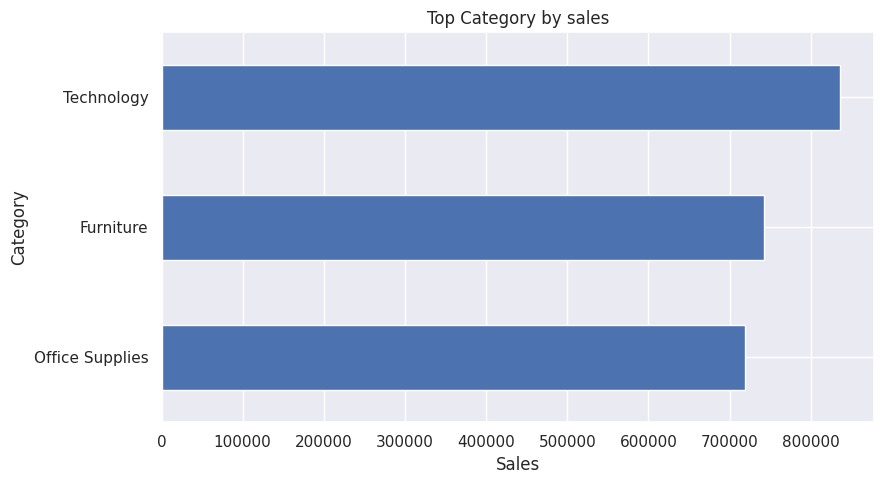

In [9]:
group_col = CATEGORY_COL if CATEGORY_COL in clean.columns else PRODUCT_COL
if group_col in clean.columns and clean["analysis_sales"].notna().any():
    performance = (clean.groupby(group_col, dropna=False)["analysis_sales"]
                   .sum().sort_values(ascending=False))
    display(performance.head(10))
    performance.head(10).sort_values().plot(kind="barh", figsize=(9,5), title=f"Top {group_col} by sales")
    plt.xlabel("Sales")
    plt.tight_layout()
    plt.show()
else:
    print("Map a product/category field and a valid sales field to run this analysis.")


## 7. Monthly sales trend

,sales
Order Date,
2014-01-01,14236.895
2014-02-01,4519.892
2014-03-01,55691.009
2014-04-01,28295.345
2014-05-01,23648.287


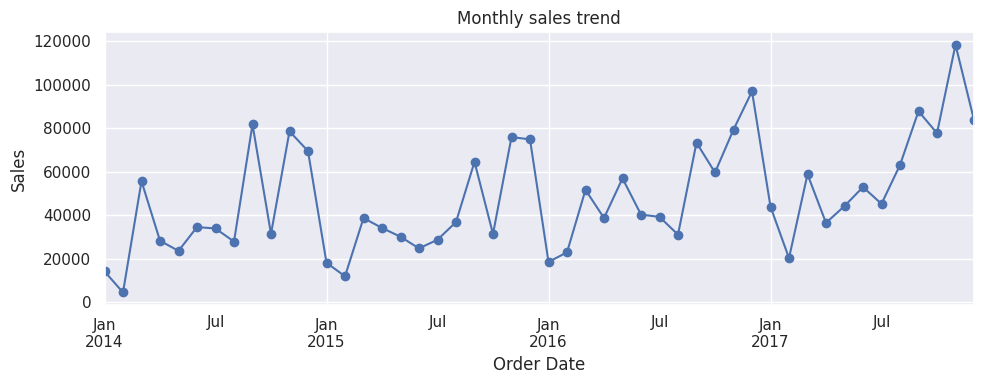

In [10]:
if DATE_COL in clean.columns and clean["analysis_sales"].notna().any():
    monthly = (clean.dropna(subset=[DATE_COL])
               .set_index(DATE_COL)["analysis_sales"]
               .resample("MS").sum())
    display(monthly.to_frame("sales").head())
    monthly.plot(figsize=(10,4), marker="o", title="Monthly sales trend")
    plt.ylabel("Sales")
    plt.tight_layout()
    plt.show()
else:
    print("Map a valid date column and sales field to run monthly trend analysis.")


# Business Insights – Retail Sales Analysis

**1. Highest Revenue Category:** Technology ($836,154.03).

**2. Strongest Sales Month:** December 2017 (verify the exact monthly value from the complete monthly sales output).

**3. Important Customer/Region Pattern:** The dataset contains 793 unique customers across four regions. Further customer and regional analysis can identify high-performing segments.

**4. Data Quality Limitations:** The dataset contains 9,994 records and 21 original columns. No missing values were detected.

**5. Recommended Business Action:** Focus on high-performing technology products, analyze low-performing categories, and use monthly sales trends for inventory and promotional planning.